# WeIntern Data Science — Week 2 Assignment
**Author:** Sankalp Padhi  
**Dataset:** Intentionally messy e-commerce sales data  
**Tasks:** Data cleaning, exploratory data analysis, and sales prediction.

> Keep `data/raw/week2_raw_ecommerce_sales.csv` unchanged. All processed files are written separately.


## 1. Setup and load raw data

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# If running from another directory, update PROJECT_ROOT to the repository root.
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "week2_raw_ecommerce_sales.csv"
CLEAN_DIR = PROJECT_ROOT / "data" / "cleaned"
CHART_DIR = PROJECT_ROOT / "outputs" / "week2_charts"
REPORT_DIR = PROJECT_ROOT / "reports" / "week2"
for folder in [CLEAN_DIR, CHART_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(RAW_PATH, dtype="object")
df = df_raw.copy()
print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)


Shape: (150, 12)


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Order Date,Payment Mode,Delivery Status,City,Customer Age,Rating
0,ORD-0001,CUST-1016,Bluetooth Speaker,Electronics,1.0,1899.0,2024-05-20,Credit Card,Shipped,Chennai,61.0,5.0
1,ORD-0002,CUST-1003,Wireless Mouse,Electronics,5.0,1899.0,2024-08-04,UPI,Delivered,Delhi,32.0,5.0
2,ORD-0003,CUST-1046,Desk Lamp,Home & Kitchen,1.0,999.0,15/02/2024,Net Banking,Cancelled,Delhi,46.0,5.0
3,ORD-0004,CUST-1045,Curtains,Electornics,1.0,1299.0,2024-03-22,Cash on Delivery,Processing,Hyderabad,27.0,2.0
4,ORD-0005,NaN,Water Bottle,Home & Kitchen,1.0,399.0,2024-02-17,UPI,Processing,Kolkata,56.0,3.0


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Order ID         150 non-null    object
 1   Customer ID      149 non-null    object
 2   Product Name     149 non-null    object
 3   Category         149 non-null    object
 4   Quantity         149 non-null    object
 5   Unit Price       148 non-null    object
 6   Order Date       149 non-null    object
 7   Payment Mode     149 non-null    object
 8   Delivery Status  149 non-null    object
 9   City             149 non-null    object
 10  Customer Age     149 non-null    object
 11  Rating           149 non-null    object
dtypes: object(12)
memory usage: 14.2+ KB


,count,unique,top,freq
Order ID,150,146,ORD-0040,2
Customer ID,149,50,CUST-1016,7
Product Name,149,11,Desk Lamp,21
Category,149,13,Electronics,43
Quantity,149,9,1.0,32
Unit Price,148,14,999.0,21
Order Date,149,123,2024-03-05,3
Payment Mode,149,7,Cash on Delivery,39
Delivery Status,149,7,Delivered,32
City,149,10,Hyderabad,24


## 2. Initial data-quality checks

In [3]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Order IDs:", df["Order ID"].duplicated(keep=False).sum())
print("Duplicate Customer IDs:", df["Customer ID"].duplicated(keep=False).sum())


Missing values by column:


,missing_count
Unit Price,2
Customer ID,1
Product Name,1
Category,1
Quantity,1
Order Date,1
Payment Mode,1
Delivery Status,1
City,1
Customer Age,1


Exact duplicate rows: 3
Duplicate Order IDs: 8
Duplicate Customer IDs: 141


## 3. Visualize missingness

In [ ]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values in Raw Dataset")
plt.xlabel("Columns")
plt.tight_layout()
plt.savefig(CHART_DIR / "week2_missing_values.png", dpi=150)
plt.show()


## 4. Clean and standardize

In [4]:
# Normalize column names to snake_case.
def to_snake_case(name):
    name = re.sub(r"[^A-Za-z0-9]+", "_", str(name).strip())
    return name.strip("_").lower()

df.columns = [to_snake_case(c) for c in df.columns]

# Trim whitespace in all text columns.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)

# Standardize common category typos and case.
category_map = {
    "electornics": "Electronics", "electronics": "Electronics",
    "ELECTRONICS": "Electronics", "home and kitchen": "Home & Kitchen",
    "home & kitchn": "Home & Kitchen", "foot wear": "Footwear",
    "clothng": "Clothing", "accessories": "Accessories"
}
df["category"] = df["category"].map(
    lambda x: category_map.get(str(x).strip().lower(), x) if pd.notna(x) else x
)

# Standardize product/city/payment/status text while preserving unknown values.
for col in ["product_name", "city", "payment_mode", "delivery_status"]:
    df[col] = df[col].map(lambda x: x.title() if isinstance(x, str) else x)
df["payment_mode"] = df["payment_mode"].replace({
    "Credit Card": "Credit Card", "Cash On Delivery": "Cash on Delivery",
    "Net Banking": "Net Banking", "Upi": "UPI"
})
df["delivery_status"] = df["delivery_status"].replace({"In Transit": "Shipped"})

# Parse dates with mixed formats; invalid dates become NaT and are documented.
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce", dayfirst=True, format="mixed")

# Coerce mixed numeric formatting to numeric values.
def numeric_clean(series):
    cleaned = series.astype("string").str.replace(r"[^0-9.\-]", "", regex=True)
    return pd.to_numeric(cleaned, errors="coerce")

for col in ["quantity", "unit_price", "customer_age", "rating"]:
    df[col] = numeric_clean(df[col])

# Remove exact duplicate rows first.
before_exact = len(df)
df = df.drop_duplicates()
exact_removed = before_exact - len(df)

# Resolve duplicate Order IDs: retain first record after exact duplicates are removed.
before_order_id = len(df)
df = df.drop_duplicates(subset=["order_id"], keep="first")
order_id_removed = before_order_id - len(df)

# Apply logical validation. Invalid values are set missing for transparent treatment.
df.loc[~df["quantity"].between(1, 100), "quantity"] = np.nan
df.loc[df["unit_price"] <= 0, "unit_price"] = np.nan
df.loc[~df["customer_age"].between(18, 100), "customer_age"] = np.nan
df.loc[~df["rating"].between(1, 5), "rating"] = np.nan

# Missing-value strategy: numeric median; categorical mode (or 'Unknown' if no mode).
for col in ["quantity", "unit_price", "customer_age", "rating"]:
    df[col] = df[col].fillna(df[col].median())
for col in ["customer_id", "product_name", "category", "payment_mode", "delivery_status", "city"]:
    mode = df[col].mode(dropna=True)
    df[col] = df[col].fillna(mode.iloc[0] if not mode.empty else "Unknown")

# Date cannot be safely inferred; drop rows without a valid order date.
before_dates = len(df)
df = df.dropna(subset=["order_date"])
invalid_date_rows_removed = before_dates - len(df)

# Derived sales amount.
df["total_amount"] = df["quantity"] * df["unit_price"]
df["order_date"] = pd.to_datetime(df["order_date"])
df = df.sort_values("order_date").reset_index(drop=True)

print(f"Exact duplicate rows removed: {exact_removed}")
print(f"Additional duplicate Order ID rows removed: {order_id_removed}")
print(f"Rows removed for invalid/missing dates: {invalid_date_rows_removed}")
print("Cleaned shape:", df.shape)
display(df.head())


Exact duplicate rows removed: 3
Additional duplicate Order ID rows removed: 1
Rows removed for invalid/missing dates: 2
Cleaned shape: (144, 13)


,order_id,customer_id,product_name,category,quantity,unit_price,order_date,payment_mode,delivery_status,city,customer_age,rating,total_amount
0,ORD-0018,CUST-1039,Running Shoes,Footwear,5.0,2499.0,2024-01-01,Debit Card,Cancelled,Bhubaneswar,25.0,3.0,12495.0
1,ORD-0027,CUST-1026,Wireless Mouse,Electronics,1.0,599.0,2024-01-02,Debit Card,Delivered,Delhi,30.0,2.0,599.0
2,ORD-0046,CUST-1012,Desk Lamp,Footwear,4.0,2499.0,2024-01-13,Debit Card,Cancelled,Delhi,35.0,2.0,9996.0
3,ORD-0101,CUST-1006,Desk Lamp,Home & Kitchen,3.0,999.0,2024-01-14,Credit Card,Returned,Bhubaneswar,61.0,3.0,2997.0
4,ORD-0075,CUST-1060,Bluetooth Speaker,Electronics,5.0,1899.0,2024-01-14,Debit Card,Shipped,Pune,43.0,2.0,9495.0


## 5. Validate and export cleaned data

In [5]:
print("Remaining missing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Remaining exact duplicates:", df.duplicated().sum())
print("Remaining duplicate Order IDs:", df["order_id"].duplicated().sum())
print("Numeric summary:")
display(df.describe().T)

clean_path = CLEAN_DIR / "week2_cleaned_ecommerce_sales.csv"
df.to_csv(clean_path, index=False)
print("Saved:", clean_path)


Remaining missing values:


,missing_count
order_id,0
customer_id,0
product_name,0
category,0
quantity,0
unit_price,0
order_date,0
payment_mode,0
delivery_status,0
city,0


Remaining exact duplicates: 0
Remaining duplicate Order IDs: 0
Numeric summary:


,count,mean,min,25%,50%,75%,max,std
quantity,144.0,3.0,1.0,2.0,3.0,4.0,5.0,1.424069
unit_price,144.0,8633.722222,399.0,999.0,1499.0,1899.0,999999.0,83197.510654
order_date,144,2024-05-18 14:10:00,2024-01-01 00:00:00,2024-03-06 00:00:00,2024-05-14 12:00:00,2024-07-29 06:00:00,2024-11-09 00:00:00,NaN
customer_age,144.0,41.993056,18.0,32.0,42.0,53.25,65.0,13.385357
rating,144.0,2.958333,1.0,2.0,3.0,4.0,5.0,1.413595
total_amount,144.0,39635.194444,399.0,2321.25,3946.5,6495.0,4999995.0,416271.98377


Saved: /Users/sankalppadhi/Documents/data-science-week1-assignment/data/cleaned/week2_cleaned_ecommerce_sales.csv


## 6. Before-and-after data quality comparison

In [7]:

quality_comparison = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing cells",
        "Exact duplicate rows",
        "Rows with duplicate Order IDs",
        "Rows with duplicate Customer IDs"
    ],
    "Raw": [
        len(df_raw),
        df_raw.shape[1],
        int(df_raw.isna().sum().sum()),
        int(df_raw.duplicated().sum()),
        int(df_raw["Order ID"].duplicated(keep=False).sum()),
        int(df_raw["Customer ID"].duplicated(keep=False).sum())
    ],
    "Cleaned": [
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df["order_id"].duplicated(keep=False).sum()),
        int(df["customer_id"].duplicated(keep=False).sum())
    ]
})

display(quality_comparison)

quality_comparison.to_csv(
    REPORT_DIR / "week2_quality_comparison.csv",
    index=False
)


,Metric,Raw,Cleaned
0,Rows,150,144
1,Columns,12,13
2,Missing cells,12,0
3,Exact duplicate rows,3,0
4,Rows with duplicate Order IDs,8,0
5,Rows with duplicate Customer IDs,141,135


## 7. Exploratory Data Analysis

In [8]:
# Descriptive statistics
display(df.describe(include="all").T)

# KPI summary
kpis = pd.DataFrame({
    "Metric": ["Total Revenue", "Total Orders", "Average Order Value", "Total Units Sold"],
    "Value": [
        df["total_amount"].sum(),
        df["order_id"].nunique(),
        df["total_amount"].sum() / max(df["order_id"].nunique(), 1),
        df["quantity"].sum()
    ]
})
display(kpis)
kpis.to_csv(REPORT_DIR / "week2_kpi_summary.csv", index=False)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,144,144,ORD-0018,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,144,49,CUST-1016,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name,144,10,Desk Lamp,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,144,5,Electronics,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,144.0,<NA>,<NA>,<NA>,3.0,1.0,2.0,3.0,4.0,5.0,1.424069
unit_price,144.0,<NA>,<NA>,<NA>,8633.722222,399.0,999.0,1499.0,1899.0,999999.0,83197.510654
order_date,144,NaN,NaN,NaN,2024-05-18 14:10:00,2024-01-01 00:00:00,2024-03-06 00:00:00,2024-05-14 12:00:00,2024-07-29 06:00:00,2024-11-09 00:00:00,NaN
payment_mode,144,5,Cash on Delivery,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery_status,144,5,Shipped,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,144,8,Kolkata,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Metric,Value
0,Total Revenue,5.707468e+06
1,Total Orders,1.440000e+02
2,Average Order Value,3.963519e+04
3,Total Units Sold,4.320000e+02


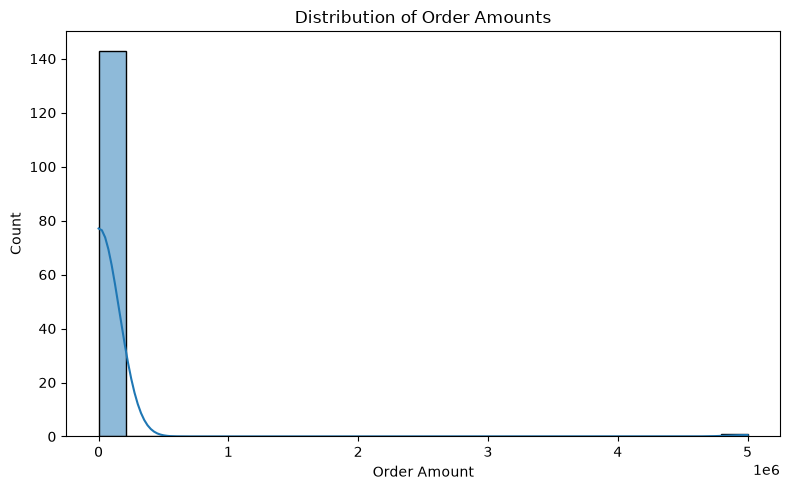

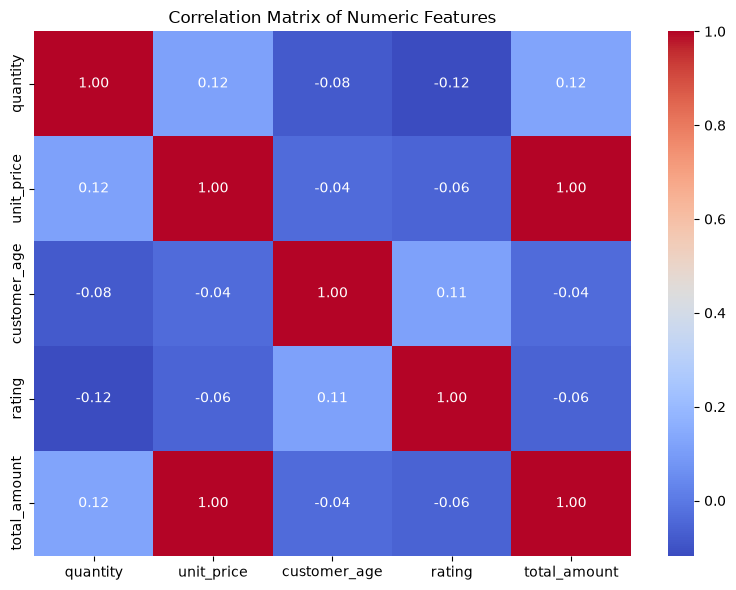

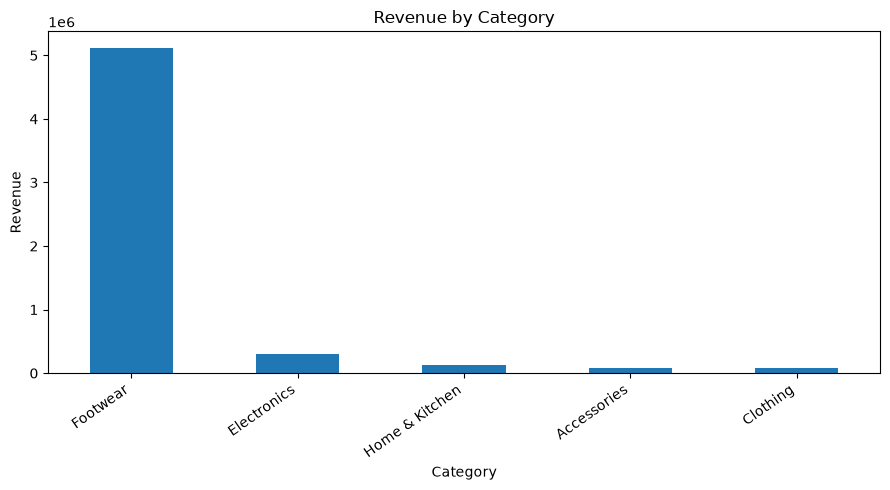

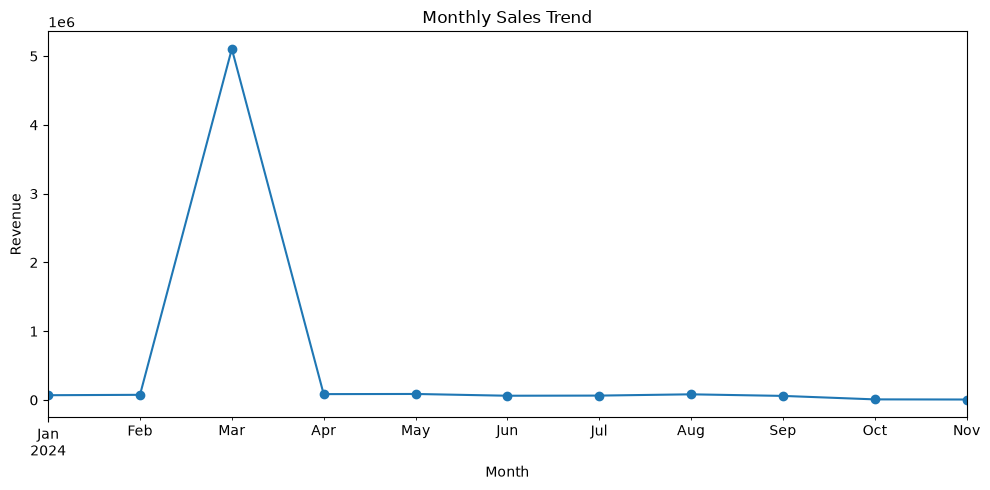

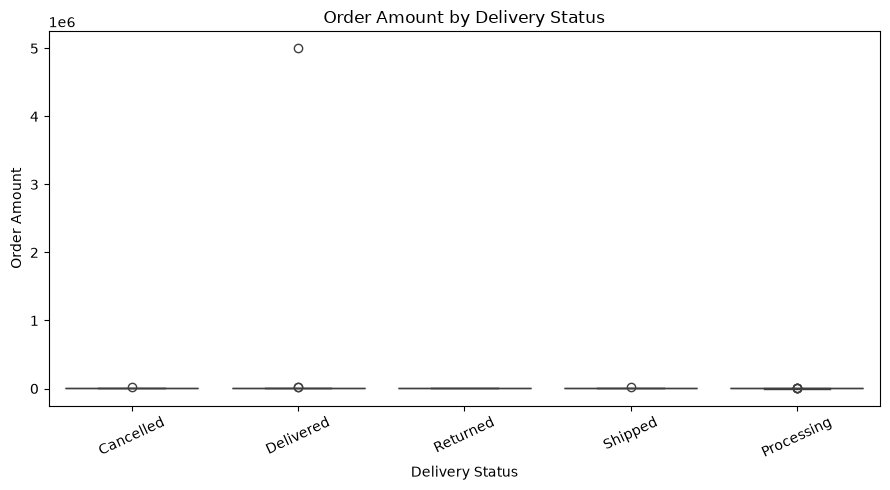

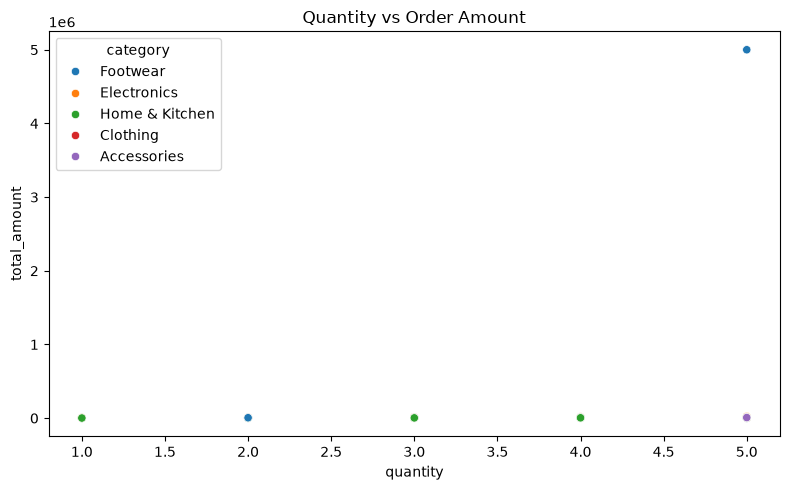

In [9]:
# 1. Histogram + KDE for sales amount
plt.figure(figsize=(8, 5))
sns.histplot(df["total_amount"], kde=True)
plt.title("Distribution of Order Amounts")
plt.xlabel("Order Amount")
plt.tight_layout()
plt.savefig(CHART_DIR / "01_order_amount_distribution.png", dpi=150)
plt.show()

# 2. Correlation heatmap
numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.savefig(CHART_DIR / "02_correlation_heatmap.png", dpi=150)
plt.show()

# 3. Revenue by category
category_revenue = df.groupby("category")["total_amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
category_revenue.plot(kind="bar")
plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(CHART_DIR / "03_revenue_by_category.png", dpi=150)
plt.show()

# 4. Monthly sales trend
monthly = df.assign(month=df["order_date"].dt.to_period("M").dt.to_timestamp()).groupby("month")["total_amount"].sum()
plt.figure(figsize=(10, 5))
monthly.plot(marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.savefig(CHART_DIR / "04_monthly_sales_trend.png", dpi=150)
plt.show()

# 5. Order amount by delivery status
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="delivery_status", y="total_amount")
plt.title("Order Amount by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Order Amount")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(CHART_DIR / "05_amount_by_delivery_status.png", dpi=150)
plt.show()

# 6. Quantity vs order amount
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="quantity", y="total_amount", hue="category")
plt.title("Quantity vs Order Amount")
plt.tight_layout()
plt.savefig(CHART_DIR / "06_quantity_vs_amount.png", dpi=150)
plt.show()


## 8. Data-driven observations

In [10]:
top_category = category_revenue.index[0]
top_city = df["city"].value_counts().index[0]
best_month = monthly.idxmax().strftime("%B %Y") if not monthly.empty else "N/A"
print(f"1. Highest revenue category: {top_category} (₹{category_revenue.iloc[0]:,.2f}).")
print(f"2. City with most recorded orders: {top_city} ({df['city'].value_counts().iloc[0]} rows).")
print(f"3. Highest revenue month: {best_month}.")
print("Interpret these as descriptive patterns in this synthetic practice dataset, not real business claims.")


1. Highest revenue category: Footwear (₹5,122,443.00).
2. City with most recorded orders: Kolkata (23 rows).
3. Highest revenue month: March 2024.
Interpret these as descriptive patterns in this synthetic practice dataset, not real business claims.


In [12]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl (20.5 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 9. Sales prediction model

In [13]:
# Predict total_amount from quantity, unit_price, category, city, payment mode,
# delivery status, customer age, rating and date-derived features.
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_df = df.copy()
model_df["order_year"] = model_df["order_date"].dt.year
model_df["order_month"] = model_df["order_date"].dt.month
model_df["order_day"] = model_df["order_date"].dt.day

target = "total_amount"
features = [
    "quantity", "unit_price", "category", "city", "payment_mode",
    "delivery_status", "customer_age", "rating", "order_year", "order_month", "order_day"
]
X = model_df[features]
y = model_df[target]

categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = [c for c in features if c not in categorical]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42, n_estimators=150)
}
results = []
fitted = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })
    fitted[name] = (pipe, pred)

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df)
results_df.to_csv(REPORT_DIR / "week2_model_comparison.csv", index=False)


,Model,MAE,RMSE,R2
1,Random Forest,648.150345,934.754183,0.929230
0,Linear Regression,1967.053245,2491.444473,0.497242


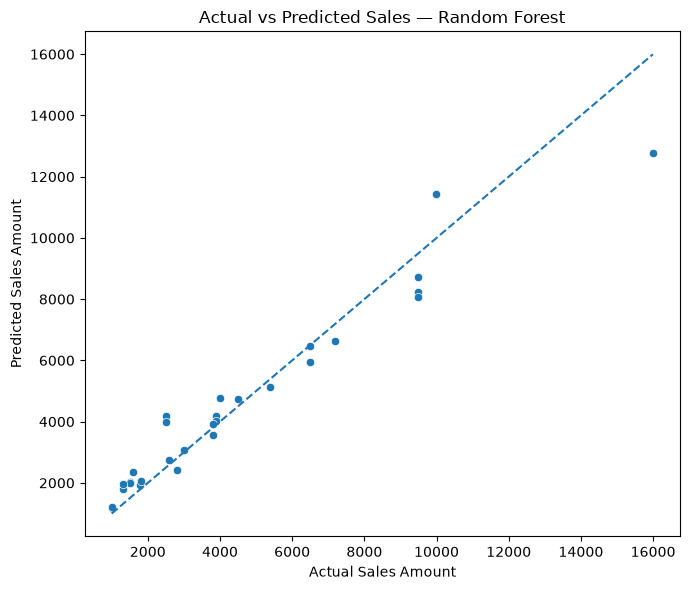

Best model by test RMSE: Random Forest
Limitations: small synthetic dataset, random train/test split, and limited historical features.


In [14]:
best_name = results_df.iloc[0]["Model"]
best_model, best_pred = fitted[best_name]
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_pred)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
plt.plot(lims, lims, linestyle="--")
plt.title(f"Actual vs Predicted Sales — {best_name}")
plt.xlabel("Actual Sales Amount")
plt.ylabel("Predicted Sales Amount")
plt.tight_layout()
plt.savefig(CHART_DIR / "07_actual_vs_predicted.png", dpi=150)
plt.show()
print("Best model by test RMSE:", best_name)
print("Limitations: small synthetic dataset, random train/test split, and limited historical features.")


## 10. Cleaning decisions and limitations
- Exact duplicate rows were removed.
- Duplicate Order IDs were reduced to one row per ID; in real data, investigate before deleting because repeated IDs can sometimes be legitimate line items.
- Category spellings and common text formatting were standardized.
- Numeric fields were parsed from mixed representations.
- Implausible quantity, price, age, and rating values were treated as missing before imputation.
- Missing numeric values were filled with medians; categorical values with modes.
- Missing or invalid order dates were dropped because dates cannot be reliably inferred.
- Outlier thresholds are business assumptions and should be confirmed with the data owner.
- This is a synthetic practice dataset. Model metrics are educational and should not be interpreted as production forecasting performance.
